# Предсказание тяжести ДТП ненаивной байесовской сетью

**Задача:** по сценарию ДТП (12 признаков) предсказать степень тяжести (`grav` → классы S0–S3).
Данные — первые 20 000 записей таблицы преподавателя `Bayes_start_table_1.xlsx`.

| Класс | grav | Значение в базе ДТП |
|---|---|---|
| S0 | 1 | Не пострадал |
| S1 | 2 | Погиб |
| S2 | 3 | Госпитализирован |
| S3 | 4 | Лёгкая травма |

Ход работы: предобработка (по коду преподавателя) → проверка данных → архитектура сети → обучение → оценка точности → предсказание для сценариев → экспорт в UnBBayes.

In [ ]:
!pip install -q pgmpy

## 1. Загрузка данных
Файл берётся с Google Диска преподавателя. Если загрузка не сработала — загрузите `Bayes_start_table_1.xlsx` вручную через панель «Файлы» слева.

In [2]:
import os, warnings, logging
import numpy as np, pandas as pd
warnings.filterwarnings('ignore'); logging.disable(logging.WARNING)

FILE = 'Bayes_start_table_1.xlsx'
if not os.path.exists(FILE):
    import gdown
    gdown.download(id='1on2V0PwKy4tJVbzCHX-MnXdbYESC_1hD', output=FILE, quiet=True)
raw = pd.read_excel(FILE)
print(raw.shape)
raw.head()

(126662, 14)


,Num_Acc,catv,manv,lum,int,atm,col,circ,prof,surf,infra,situ,catr,grav
0,2.022000e+11,2.0,9.0,1.0,3.0,1.0,3.0,2.0,1.0,1.0,0.0,1.0,4.0,3
1,2.022000e+11,7.0,1.0,1.0,3.0,1.0,3.0,2.0,1.0,1.0,0.0,1.0,4.0,1
2,2.022000e+11,7.0,15.0,1.0,6.0,1.0,2.0,-1.0,1.0,1.0,5.0,1.0,3.0,4
3,2.022000e+11,10.0,1.0,1.0,3.0,8.0,6.0,1.0,2.0,1.0,0.0,1.0,4.0,1
4,2.022000e+11,7.0,2.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,0.0,1.0,3.0,1


## 2. Предобработка (по коду преподавателя `23.py`)
- первые 20 000 записей;
- только категории ТС из списка `values1` и тяжесть 1–4;
- `grav` → `Severity` (S0–S3).

`INCLUDE_CARS = True` добавляет легковые автомобили (`catv = 7`), которых нет в списке преподавателя.

In [3]:
INCLUDE_CARS = False

df = raw.iloc[:20000].copy()
values1 = [0, 1, 2, 33, 10, 13, 14, 15, 99, 37, 3, 35, 36, 39, 40] + ([7] if INCLUDE_CARS else [])
values2 = [1, 2, 3, 4]
df = df[df.catv.isin(values1) & df.grav.isin(values2)].reset_index(drop=True)
df['Severity'] = df.grav.map({1: 'S0', 2: 'S1', 3: 'S2', 4: 'S3'})
df = df.drop(columns='grav')

FEATURES = ['catv', 'manv', 'lum', 'int', 'atm', 'col', 'circ', 'prof', 'surf', 'infra', 'situ', 'catr']
data = df[FEATURES].astype(int).astype(str)       # категории как строки: '-1', '7', ...
data['Severity'] = df.Severity
print('Записей после фильтра:', len(data), '| аварий:', df.Num_Acc.nunique())
print(data.Severity.value_counts(normalize=True).sort_index().round(3).to_dict())

Записей после фильтра: 5727 | аварий: 5016
{'S0': 0.443, 'S1': 0.026, 'S2': 0.154, 'S3': 0.377}


## 3. Проверка данных
Условия ДТП (освещённость, погода, тип дороги) одинаковы для всех участников одной аварии. Если в одной аварии они «разные» — строки таблицы перепутаны.

In [4]:
full = raw.iloc[:20000]
g = full.groupby('Num_Acc')
for c in ['lum', 'atm', 'catr', 'col']:
    print(f'{c:5s}: у {100 * (g[c].nunique() > 1).mean():.0f}% аварий разные значения')
print()
print('Строк с заполненными catv/manv (таблица ТС):      ', raw.catv.notna().sum())
print('Строк с заполненными lum…catr (таблица аварий):  ', raw.lum.notna().sum())
print('Строк с grav (таблица участников):               ', len(raw))
print('Уникальных номеров аварий:                       ', raw.Num_Acc.nunique())

lum  : у 33% аварий разные значения
atm  : у 22% аварий разные значения
catr : у 38% аварий разные значения
col  : у 49% аварий разные значения

Строк с заполненными catv/manv (таблица ТС):       94493
Строк с заполненными lum…catr (таблица аварий):   55302
Строк с grav (таблица участников):                126662
Уникальных номеров аварий:                        55302


**Вывод:** столбцы склеены из трёх таблиц разной длины по номеру строки, а не по `Num_Acc`. Признаки и тяжесть в одной строке относятся к разным авариям, поэтому сильной связи между ними ожидать нельзя. Это ограничение исходных данных; ниже мы честно измеряем, что из них можно извлечь.

## 4. Архитектура сети
Сеть **ненаивная**: признаки связаны не только с целевым узлом, но и между собой (причинные связи).

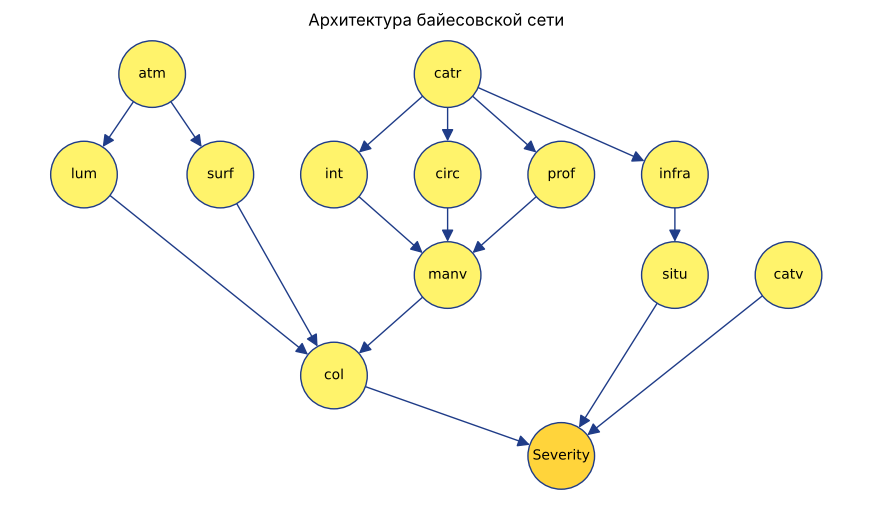

In [5]:
EDGES = [
    ('catr', 'int'), ('catr', 'circ'), ('catr', 'infra'), ('catr', 'prof'),   # тип дороги определяет её устройство
    ('atm', 'surf'), ('atm', 'lum'),                                          # погода → покрытие и освещённость
    ('int', 'manv'), ('circ', 'manv'), ('prof', 'manv'),                      # перекрёсток, режим, уклон → манёвр
    ('manv', 'col'), ('surf', 'col'), ('lum', 'col'),                         # манёвр, покрытие, видимость → тип столкновения
    ('infra', 'situ'),                                                        # инфраструктура → место аварии
    ('col', 'Severity'), ('catv', 'Severity'), ('situ', 'Severity'),          # → тяжесть
]
import matplotlib.pyplot as plt, networkx as nx
G = nx.DiGraph(EDGES)
pos = {'atm': (-0.6, 3), 'catr': (2.0, 3),
       'lum': (-1.2, 2), 'surf': (0.0, 2), 'int': (1.0, 2), 'circ': (2.0, 2), 'prof': (3.0, 2), 'infra': (4.0, 2),
       'manv': (2.0, 1), 'situ': (4.0, 1), 'catv': (5.0, 1),
       'col': (1.0, 0), 'Severity': (3.0, -0.8)}
plt.figure(figsize=(11, 6))
nx.draw_networkx(G, pos, node_size=2300, node_color=['#ffd43b' if n == 'Severity' else '#fff36b' for n in G],
                 edgecolors='#1f3c88', arrowsize=18, font_size=10, edge_color='#1f3c88')
plt.title('Архитектура байесовской сети'); plt.axis('off'); plt.show()

## 5. Обучение
- Разбиение 80/20 **по авариям** (записи одной аварии не попадают одновременно в обучение и тест).
- Таблицы вероятностей — байесовская оценка с априорным распределением BDeu: к каждой ячейке добавляется немного «псевдонаблюдений», чтобы редкие комбинации не получали вероятность 0.

In [6]:
from sklearn.model_selection import GroupShuffleSplit
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator

STATES = {c: sorted(data[c].unique(), key=lambda s: (len(s), s)) for c in data.columns}
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(data, groups=df.Num_Acc))
train, test = data.iloc[tr], data.iloc[te]

def fit(edges, d):
    m = DiscreteBayesianNetwork(edges); m.add_nodes_from(data.columns)
    m.add_cpds(*BayesianEstimator(m, d, state_names=STATES).get_parameters(prior_type='BDeu', equivalent_sample_size=5))
    assert m.check_model()
    return m

model = fit(EDGES, train)
print('Обучающих записей:', len(train), '| тестовых:', len(test))
print(model.get_cpds('Severity'))

Обучающих записей: 4610 | тестовых: 1117


+--------------+-----+----------+----------+----------+
| catv         | ... | catv(99) | catv(99) | catv(99) |
+--------------+-----+----------+----------+----------+
| col          | ... | col(-1)  | col(-1)  | col(-1)  |
+--------------+-----+----------+----------+----------+
| situ         | ... | situ(6)  | situ(8)  | situ(-1) |
+--------------+-----+----------+----------+----------+
| Severity(S0) | ... | 0.25     | 0.25     | 0.25     |
+--------------+-----+----------+----------+----------+
| Severity(S1) | ... | 0.25     | 0.25     | 0.25     |
+--------------+-----+----------+----------+----------+
| Severity(S2) | ... | 0.25     | 0.25     | 0.25     |
+--------------+-----+----------+----------+----------+
| Severity(S3) | ... | 0.25     | 0.25     | 0.25     |
+--------------+-----+----------+----------+----------+


## 6. Предсказание и оценка точности
Когда известны все признаки, P(Severity | признаки) зависит только от **марковского одеяла** узла Severity — его родителей (col, catv, situ). Используем точный вывод `VariableElimination`.

In [7]:
from pgmpy.inference import VariableElimination
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def predict_proba(m, X):
    inf = VariableElimination(m)
    cache, out = {}, []
    for _, r in X.iterrows():
        key = tuple(r)
        if key not in cache:
            q = inf.query(['Severity'], evidence=dict(r), show_progress=False)
            cache[key] = q.values
        out.append(cache[key])
    return np.array(out)

P = predict_proba(model, test[FEATURES])
pred = np.array(STATES['Severity'])[P.argmax(1)]
base = train.Severity.mode()[0]
print(f'Точность сети:                         {accuracy_score(test.Severity, pred):.3f}')
print(f'Точность «всегда {base}» (базовая линия):  {(test.Severity == base).mean():.3f}')
print(f'Macro-F1 сети:                         {f1_score(test.Severity, pred, average="macro"):.3f}')
print(pd.DataFrame(confusion_matrix(test.Severity, pred, labels=STATES['Severity']),
                   index=['факт ' + s for s in STATES['Severity']], columns=['прогноз ' + s for s in STATES['Severity']]))

Точность сети:                         0.425
Точность «всегда S0» (базовая линия):  0.420
Macro-F1 сети:                         0.206
         прогноз S0  прогноз S1  прогноз S2  прогноз S3
факт S0         399           0           4          66
факт S1          26           0           0           4
факт S2         156           0           1          23
факт S3         358           1           4          75


### Сравнение с наивной сетью и структурой, найденной по данным

In [8]:
from pgmpy.estimators import HillClimbSearch
naive = fit([('Severity', f) for f in FEATURES], train)
pn = np.array(STATES['Severity'])[predict_proba(naive, test[FEATURES]).argmax(1)]
print(f'Наивная сеть: точность {accuracy_score(test.Severity, pn):.3f}')

hc = HillClimbSearch(train).estimate(scoring_method='bic-d', max_indegree=3, show_progress=False)
print('Hill Climb (BIC) нашёл связи:', sorted(hc.edges()))
print('Связи с Severity:', [e for e in hc.edges() if 'Severity' in e] or 'нет — тяжесть не зависит от признаков в этих данных')

Наивная сеть: точность 0.418


Hill Climb (BIC) нашёл связи: [('atm', 'surf'), ('catr', 'lum'), ('circ', 'catr'), ('col', 'circ'), ('col', 'int'), ('int', 'infra'), ('situ', 'col')]
Связи с Severity: нет — тяжесть не зависит от признаков в этих данных


## 7. Предсказание для сценария
Задаём известные условия (свидетельства) — сеть пересчитывает распределение тяжести.

In [9]:
final = fit(EDGES, data)          # итоговая модель на всех данных
inf = VariableElimination(final)

def scenario(**ev):
    q = inf.query(['Severity'], evidence={k: str(v) for k, v in ev.items()}, show_progress=False)
    return pd.Series(q.values, index=q.state_names['Severity']).round(3)

table = pd.DataFrame({
    'без информации':                 scenario(),
    'мотоцикл >125 см³ (catv=33)':    scenario(catv=33),
    'велосипед (catv=1)':             scenario(catv=1),
    'фронтальное столкновение (col=1)': scenario(col=1),
    'мотоцикл + фронтальное':         scenario(catv=33, col=1),
}).T
table

,S0,S1,S2,S3
без информации,0.439,0.034,0.156,0.370
мотоцикл >125 см³ (catv=33),0.439,0.031,0.149,0.381
велосипед (catv=1),0.451,0.031,0.151,0.367
фронтальное столкновение (col=1),0.472,0.028,0.125,0.375
мотоцикл + фронтальное,0.502,0.026,0.099,0.373


## 8. Экспорт в UnBBayes
Сохраняем сеть в формате Hugin `.net` (File → Open в UnBBayes).

In [10]:
def to_hugin(m, path):
    pos_xy = {n: (int(80 + 160 * (x + 1)), int(40 + 110 * (3 - y))) for n, (x, y) in pos.items()}
    out = ['net\n{\n    node_size = (110 50);\n}\n']
    for n in m.nodes():
        st = ' '.join(f'"{s}"' for s in STATES[n])
        out.append(f'node {n}\n{{\n    label = "{n}";\n    position = {pos_xy[n]};\n    states = ({st});\n}}\n'.replace(',', ''))
    def nest(a):
        return '(' + (' '.join(f'{v:.6f}' for v in a) if a.ndim == 1 else ' '.join(nest(x) for x in a)) + ')'
    for n in m.nodes():
        cpd = m.get_cpds(n); par = cpd.variables[1:]
        vals = np.moveaxis(cpd.values, 0, -1)            # (родители…, состояние узла)
        head = f'potential ({n} | {" ".join(par)})' if par else f'potential ({n})'
        out.append(f'{head}\n{{\n    data = {nest(vals)};\n}}\n')
    open(path, 'w').write('\n'.join(out))

to_hugin(final, 'dtp.net')
print('Сохранено: dtp.net — скачайте через панель «Файлы»')

Сохранено: dtp.net — скачайте через панель «Файлы»
